# ROM for SWE using the EA-POD-NN method

## The 2-D SWEs system:

$$\begin{equation} \label{eq:SWe}
(\mathcal{M}_{\mu}) \left\{ \begin{array}{lll}
\partial_{t}h+div(\mathbf{q}) & =  0 & \textrm{ in } \Omega~ \times ~]0,T]\\
\partial_{t}\mathbf{q}+div\left(\dfrac{\mathbf{q}\otimes\mathbf{q}}{h}+g\dfrac{h^{2}}{2}Id\right) & =  S_g(\mu; h) + S_f(\mu; h, \mathbf{q}) & \textrm{ in } \Omega~ \times ~]0,T] \\
\mbox{Plus Initial Conditions, } & \mbox{ plus Boundary Conditions (B.C.)($\mu$)}& 
\end{array}\right..
\end{equation} $$

## The main code that call all defined classes

### Source librairies

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from parameter_generator import HydrographGenerator
from Parallel_code import DassFlowRunner
import shutil
import multiprocessing
from multiprocessing import Manager, Pool
import logging
import os
from POD_Basis import PODProcessor
from POD_Basis_error import PODProcessor_error
from EA_POD_NN_offline import POD_NN_METHOD
from EA_POD_NN_online import POD_NN_PREDICTION
from Aude_test_case_online_jupyter import DassflowSimulation

2024-02-15 17:05:02.297381: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-15 17:05:02.323339: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-15 17:05:02.323359: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-15 17:05:02.324106: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-15 17:05:02.328460: I tensorflow/core/platform/cpu_feature_guar

### Define the parameters for the defined classes

In [2]:
# Hydrograph Generator Parameters
hydrograph_params = {
    'constraint_values': ([31200., 1100., 30200., 300.], 0.035),
    'mu1_range': np.linspace(75000, 100000, 5),
    'mu2_range': np.linspace(600, 1200, 5),
    'mu3_range': np.linspace(50000, 80000, 5),
    'mu4_range': np.linspace(100, 400, 5),
    'tmontee1': 46800.,
    'tmontee2': 46800.,
    'param': np.array([31200., 1100., 30200., 300.]),
    'n':48,
    
}

# RB matrices construction parameters
# For Brb
pod_params = {
    'M': 30,
    'Nt': 500,
    'Nh': 7267,
    'epsilon_POD': 1e-3,
    'data_directory': '/home-local/allabou/Bureau/These/Code/Code_reduction/model_outputs/'
} 

# For Ber
pod_params_er = {
    'epsilon_er': 1e-2,
} 

# Definte the parameters for the Neural Network (NN)
my_nn_params = {
        'input_dim':None,
        'Nrb': None,
        'Ner': None,
        'Neurons': 20,
        'Neurons_er': None,
        'epochs': 1000,
        'batch_size': 10,
        'lr': 0.001,
        'alpha': 0.2,
        'alpha1': 0.1
}

# DassFlowRunner Parameters
dassflow_params = {
    'run_type': "direct",
    'ts': 216000.,
    'dtw': 2160.,
    'Qin1': None,
    'Qin2': None,
    'dassflow_dir': "/home-local/allabou/Bureau/dasshydro-main",
    'save_dir': "/home-local/allabou/Bureau/These/Code/Code_reduction/model_outputs",
    'code_dir': "/home-local/allabou/Bureau/dasshydro-main/code/",
    'bin_dir': "/home-local/allabou/Bureau/dasshydro-main/code/bin_A/",
}

### The main code to perform the SWE reduction using the EA-POD-NN method

The point is good with constraint: 0.03205128205128205


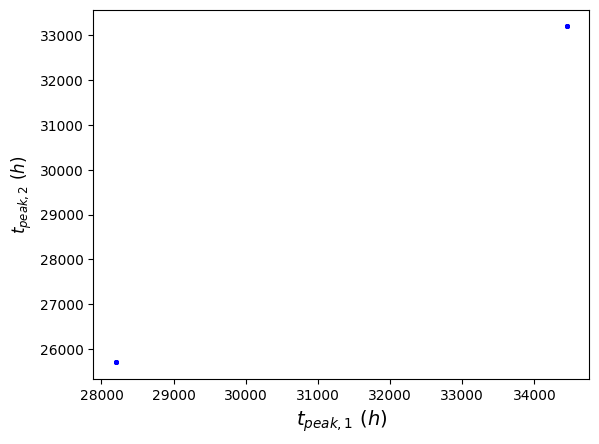

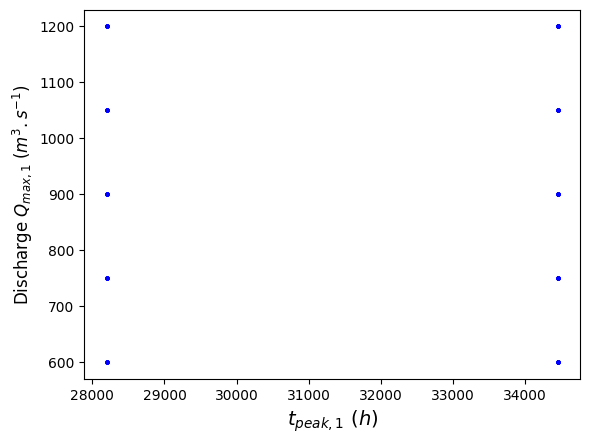

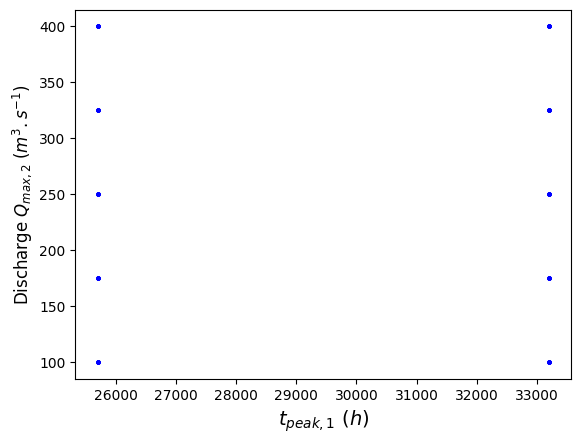

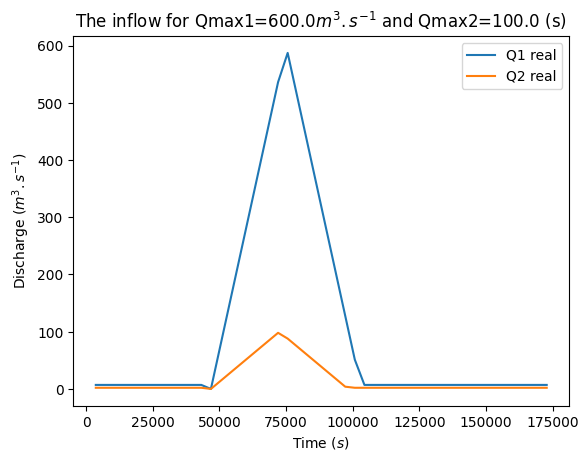

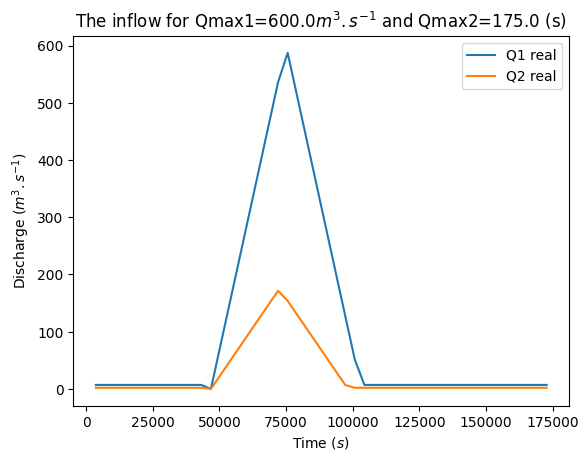

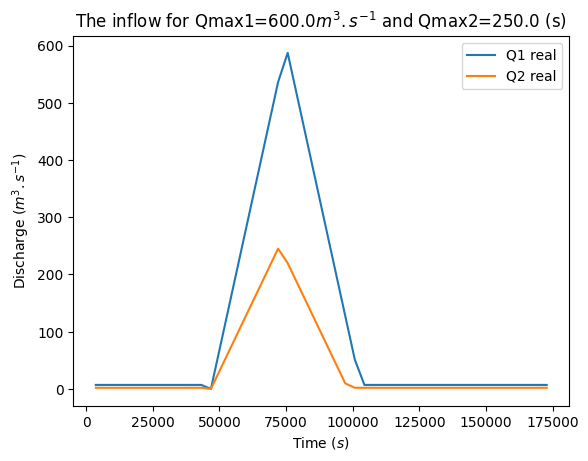

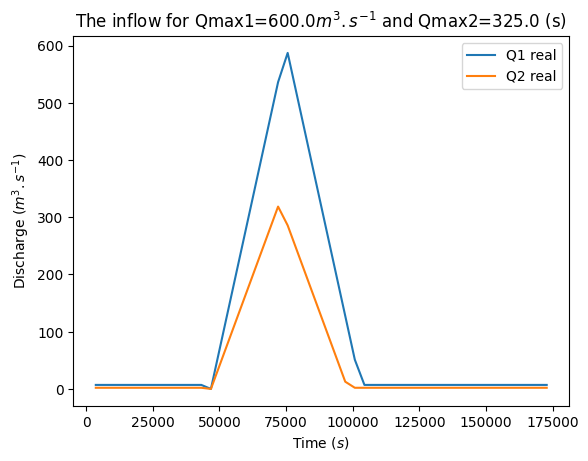

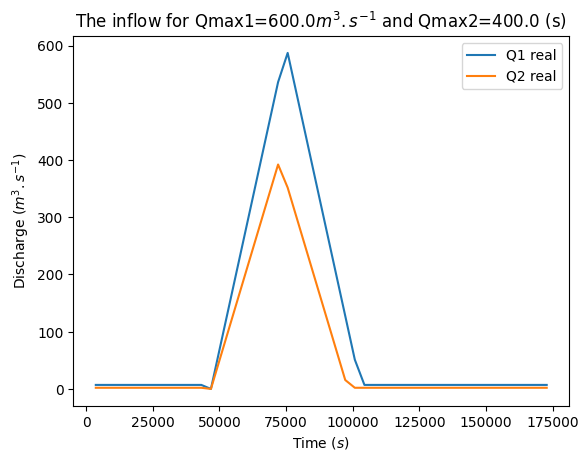

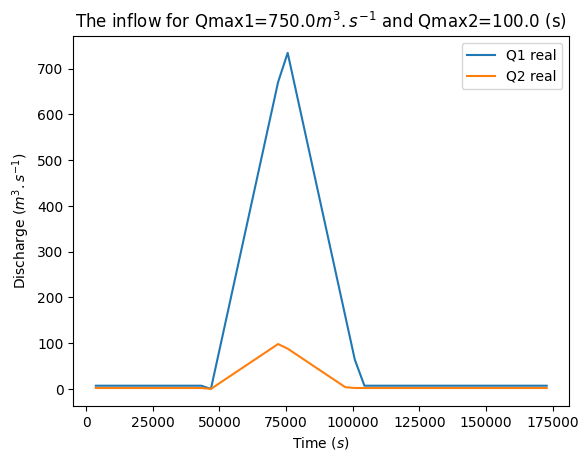

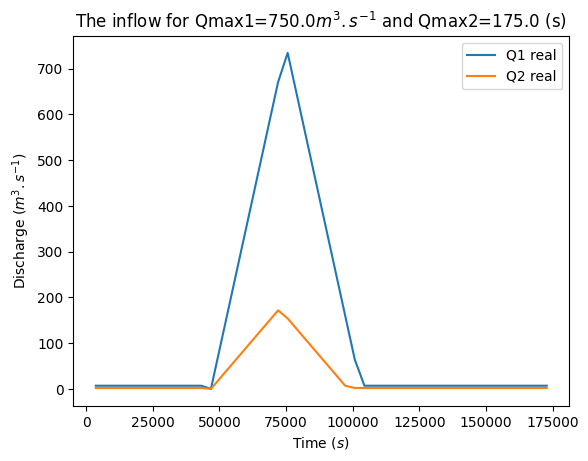

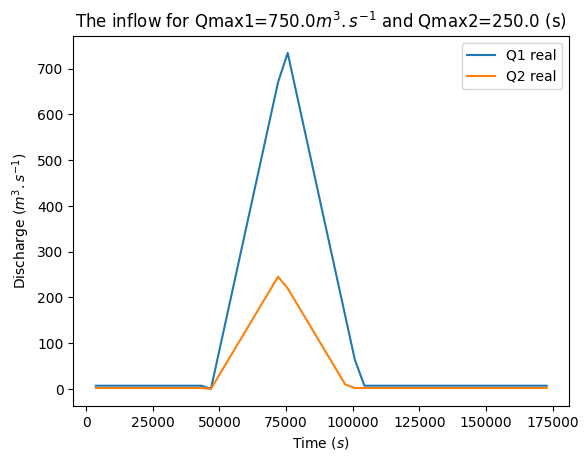

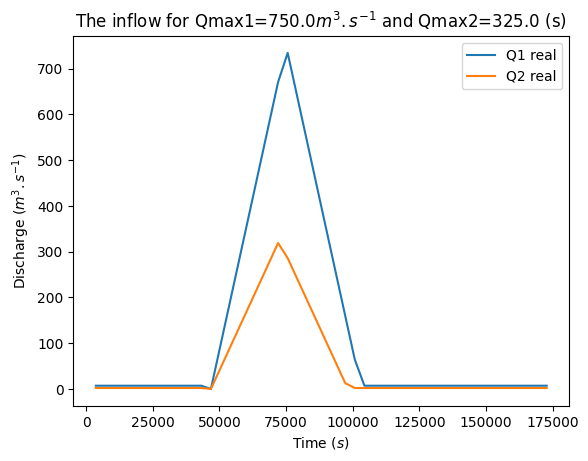

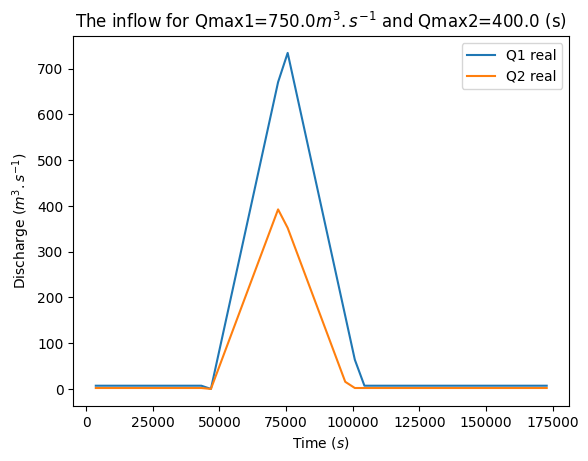

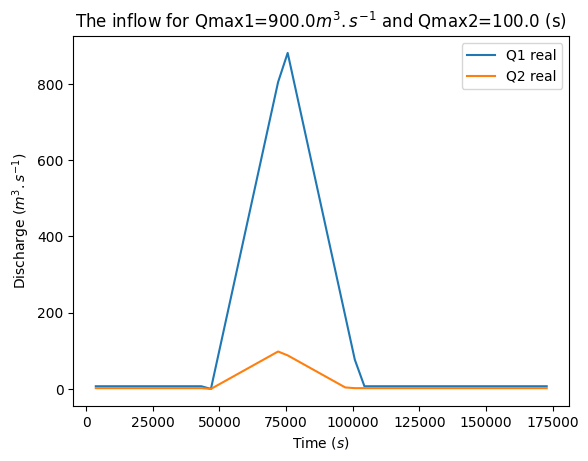

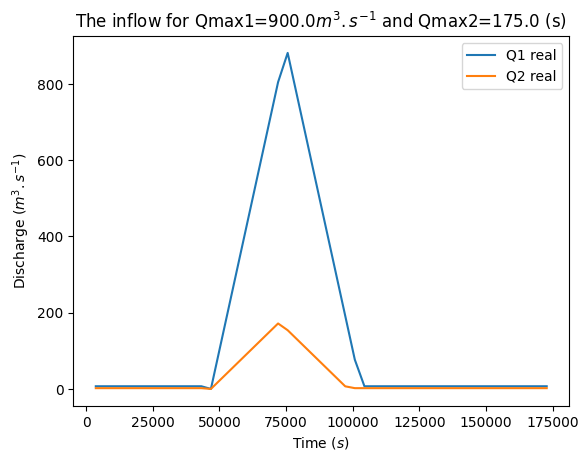

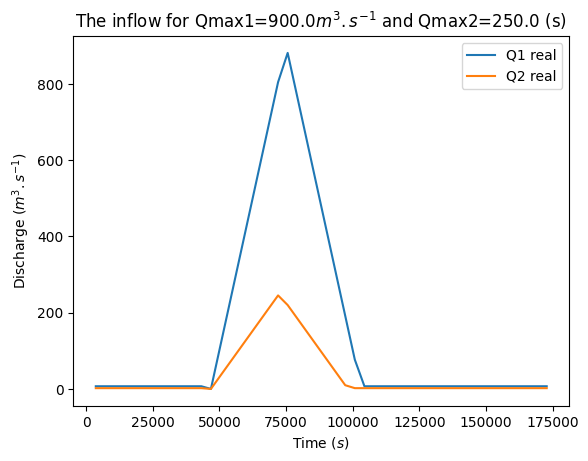

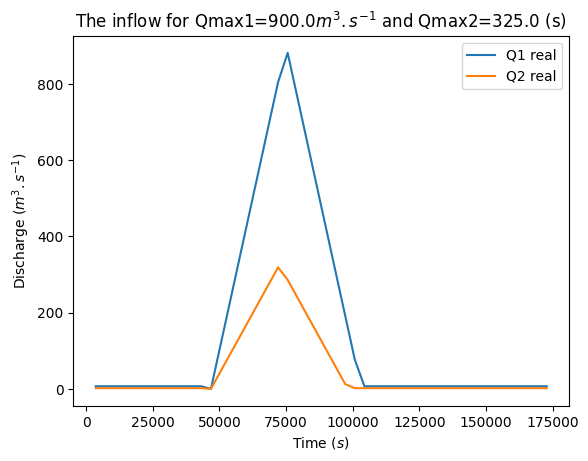

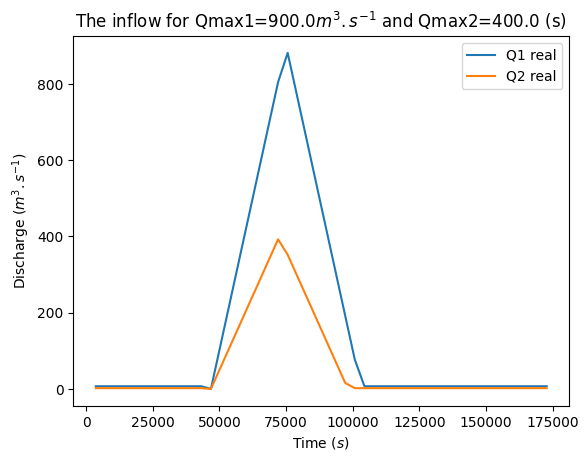

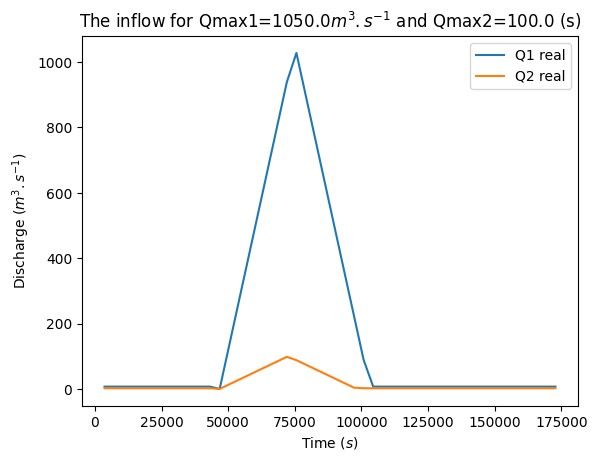

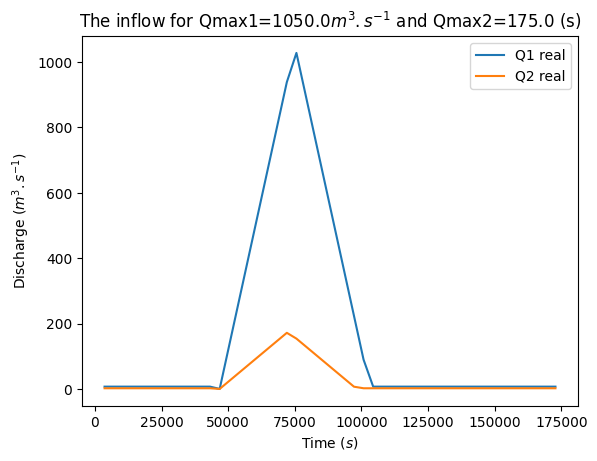

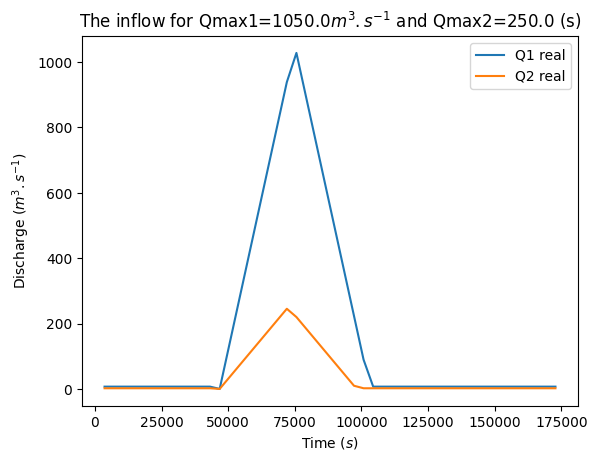

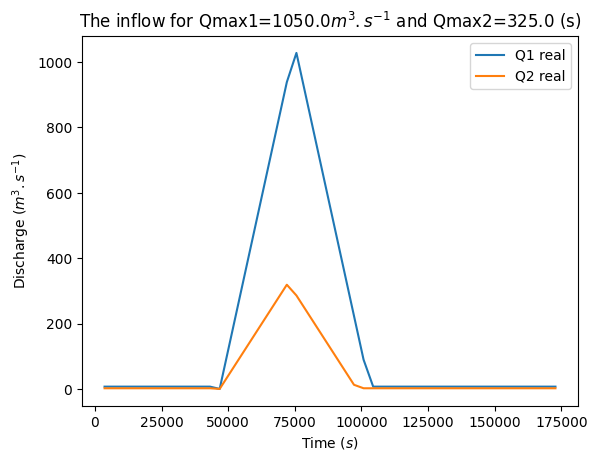

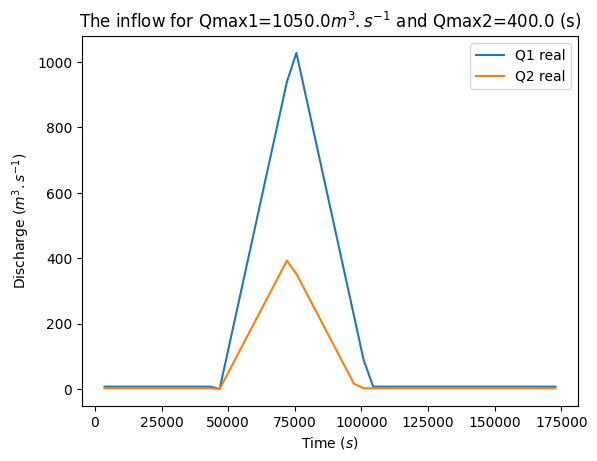

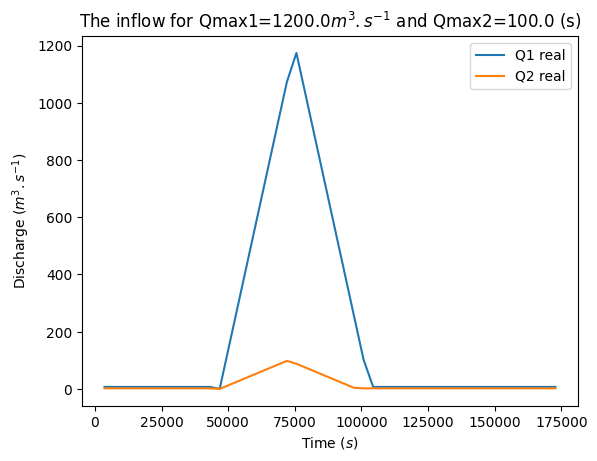

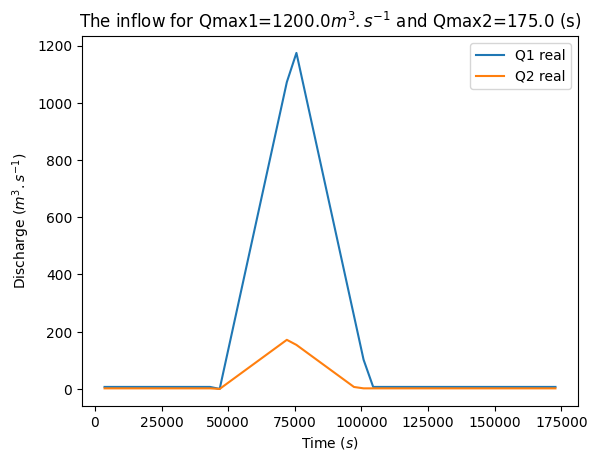

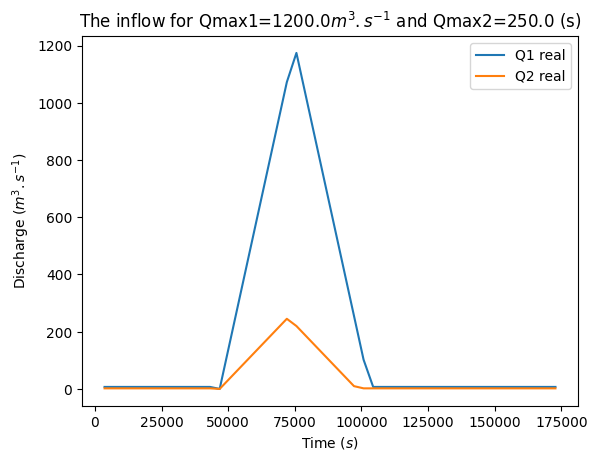

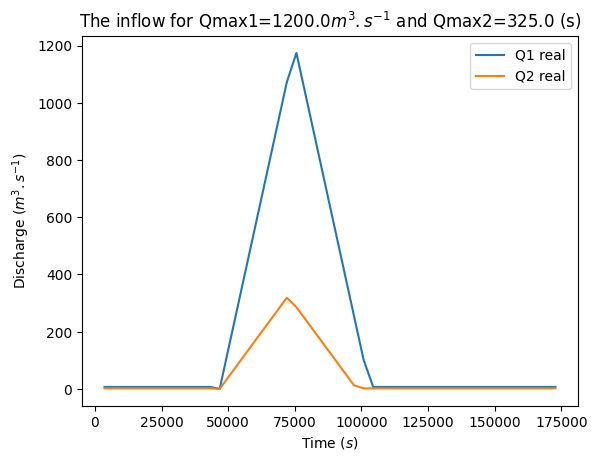

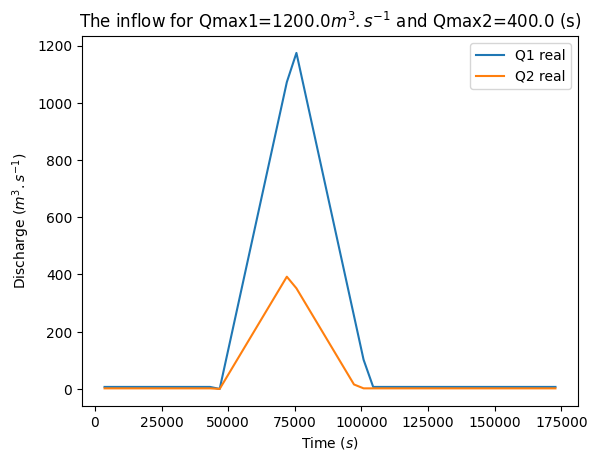

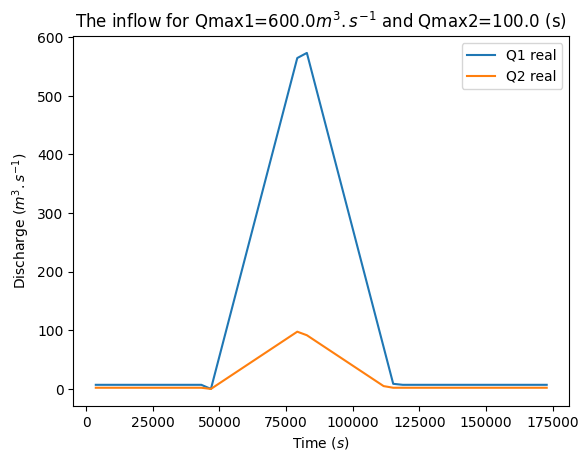

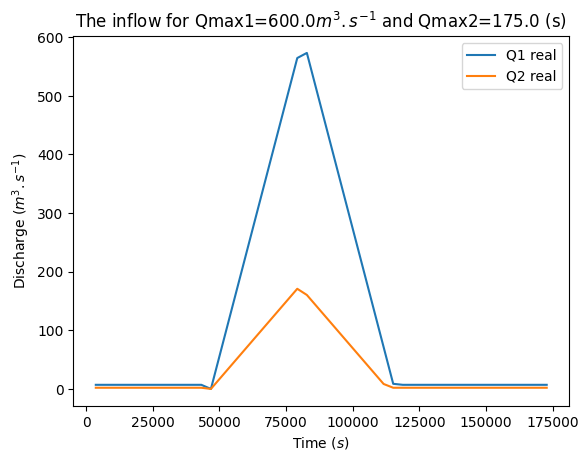

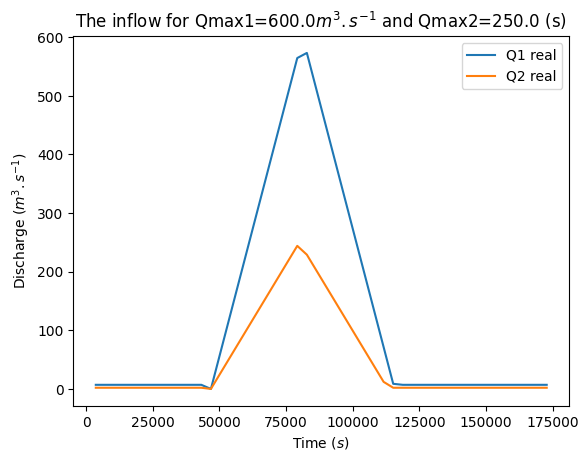

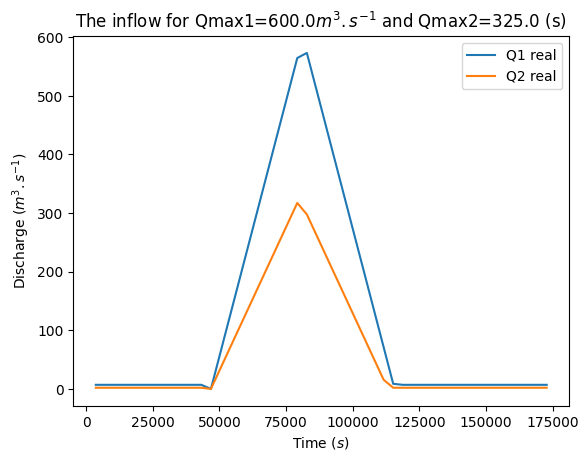

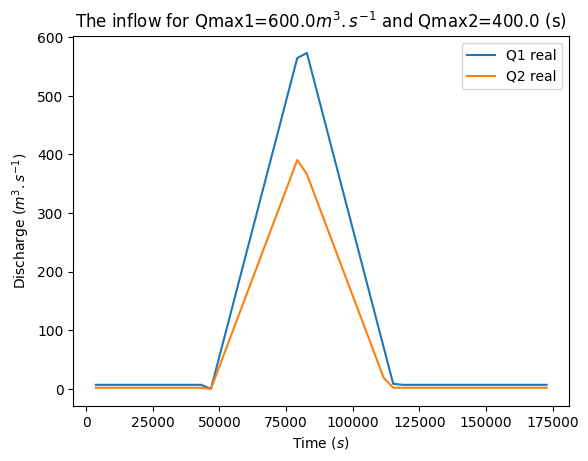

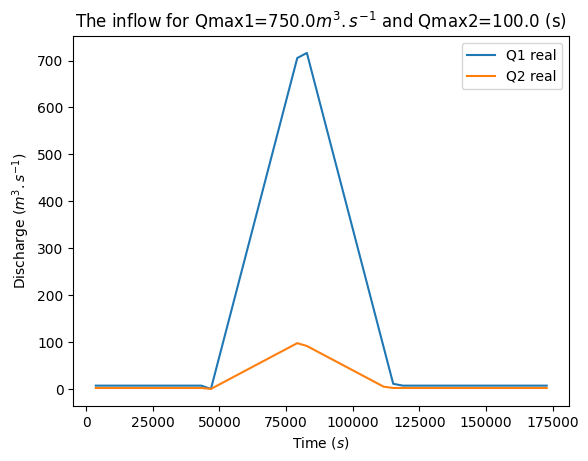

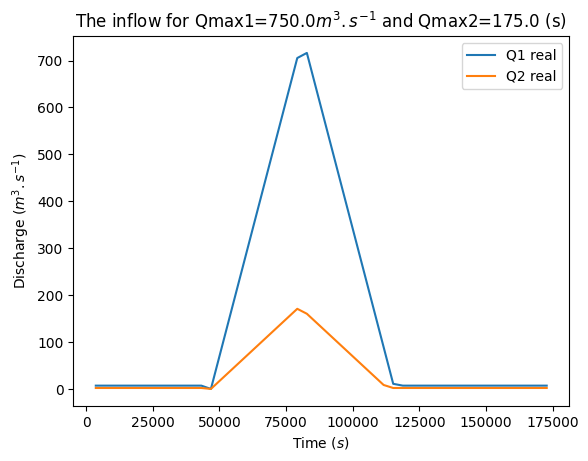

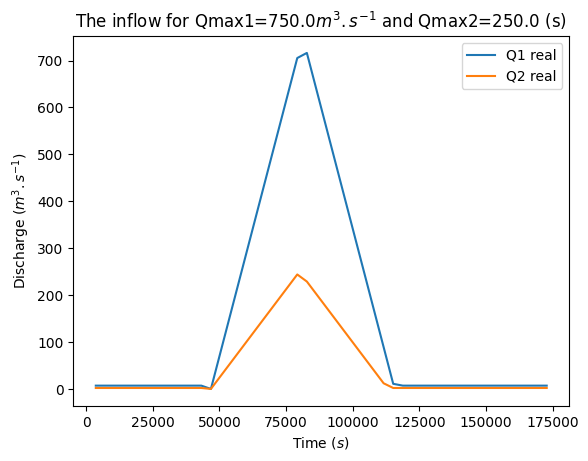

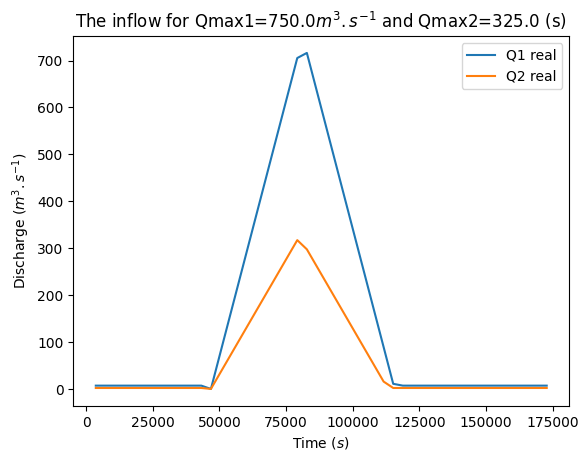

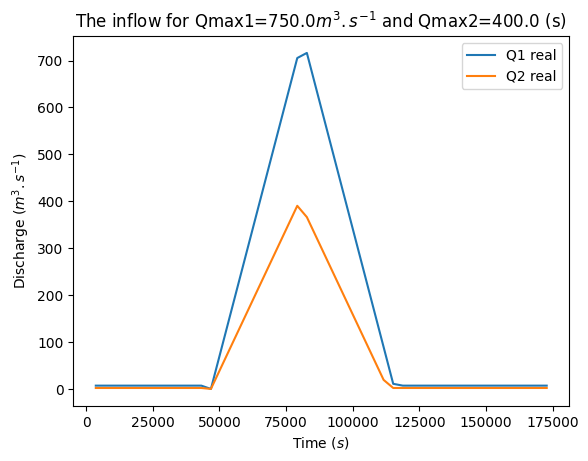

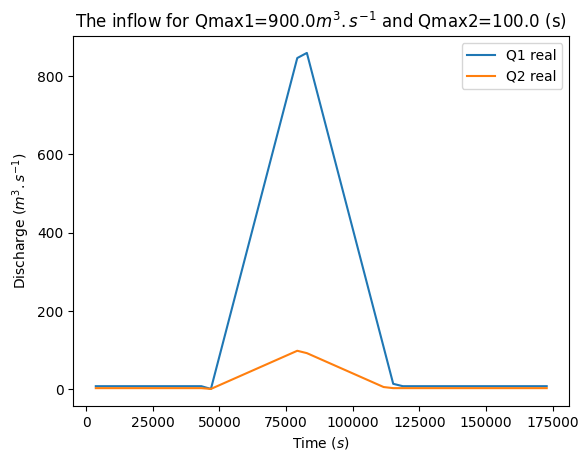

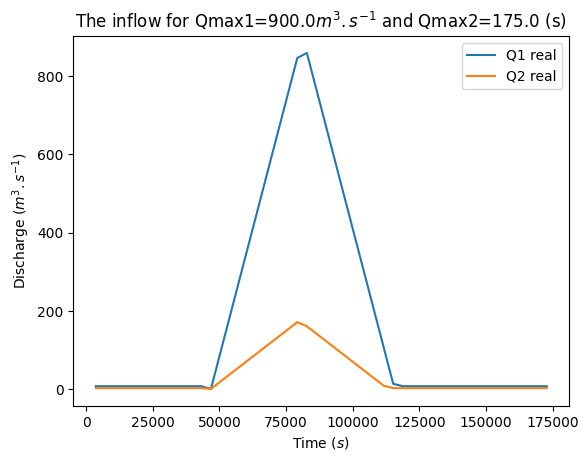

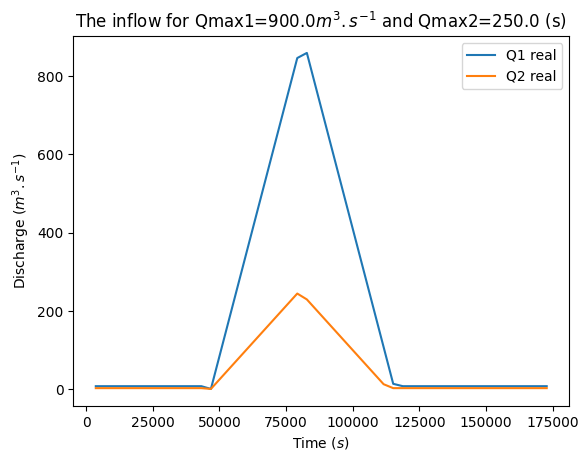

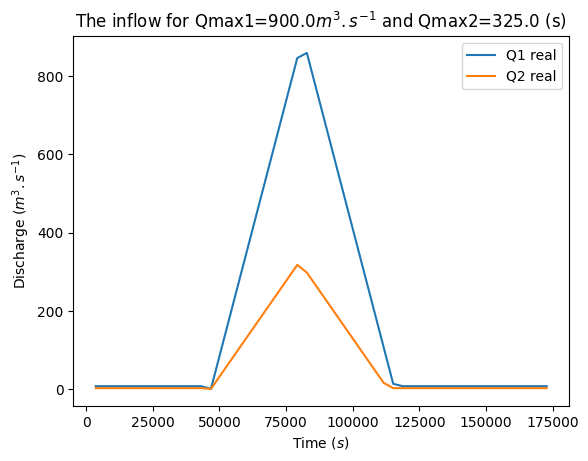

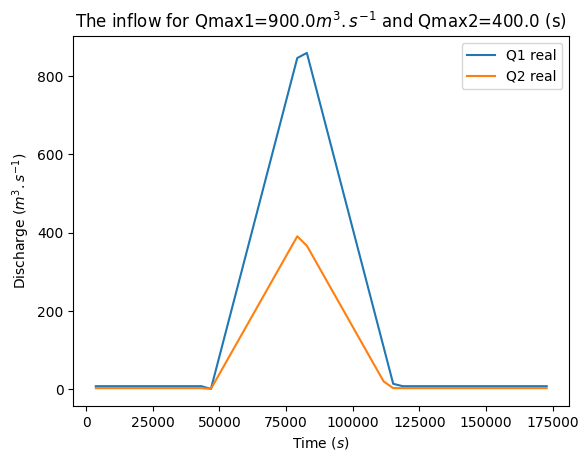

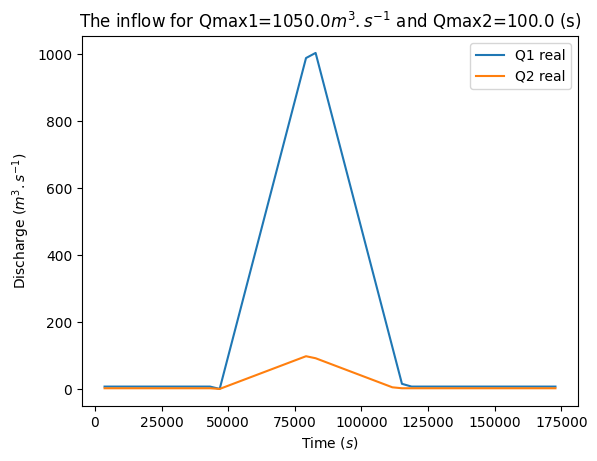

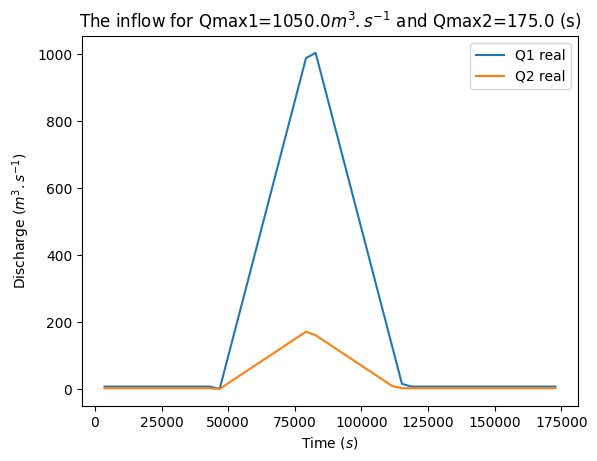

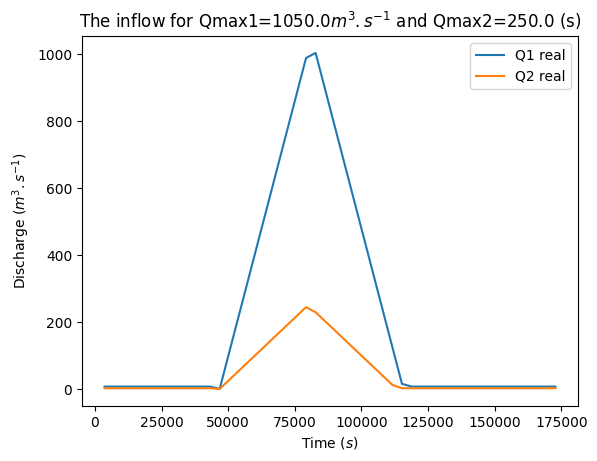

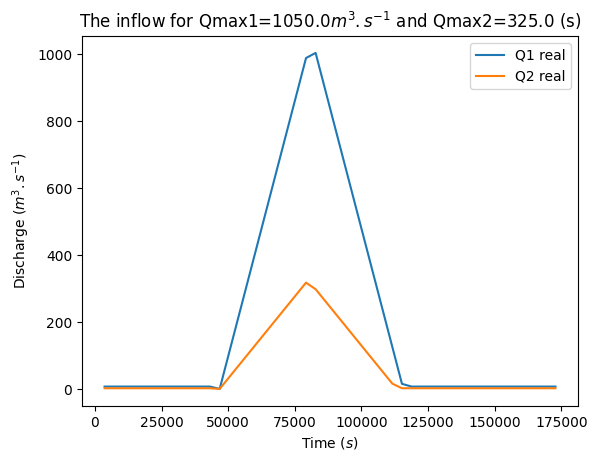

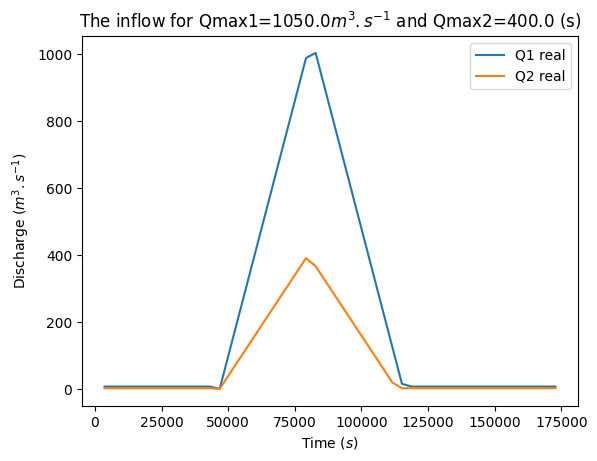

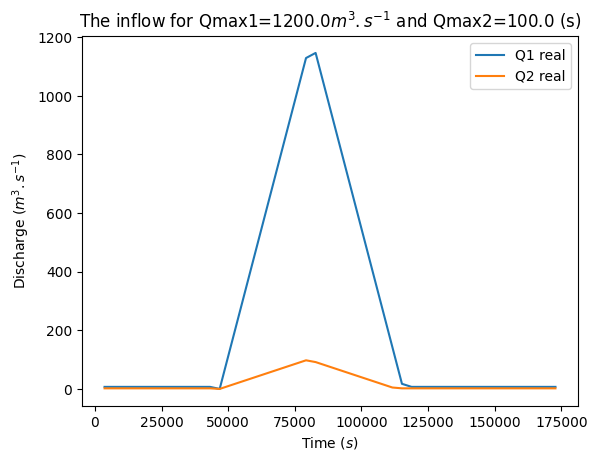

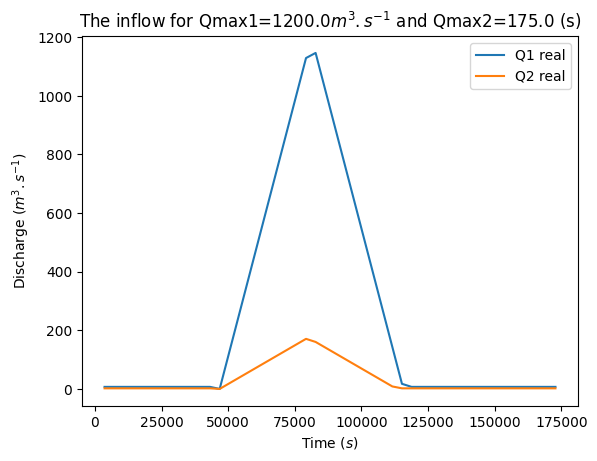

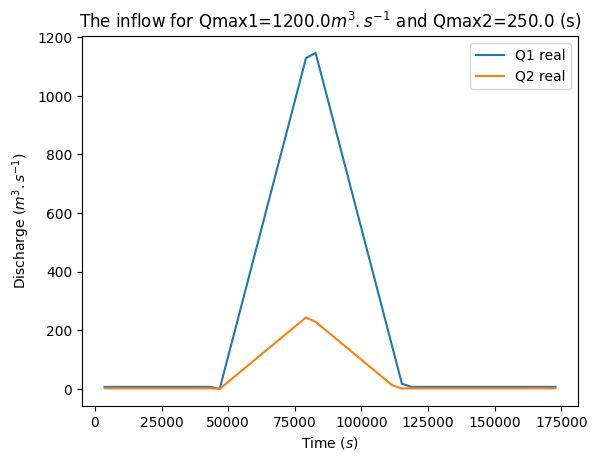

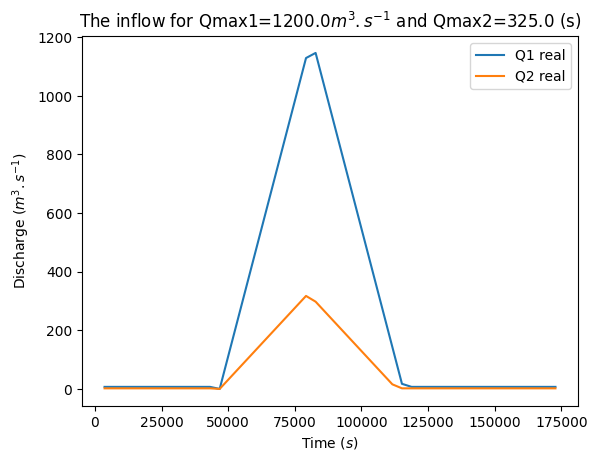

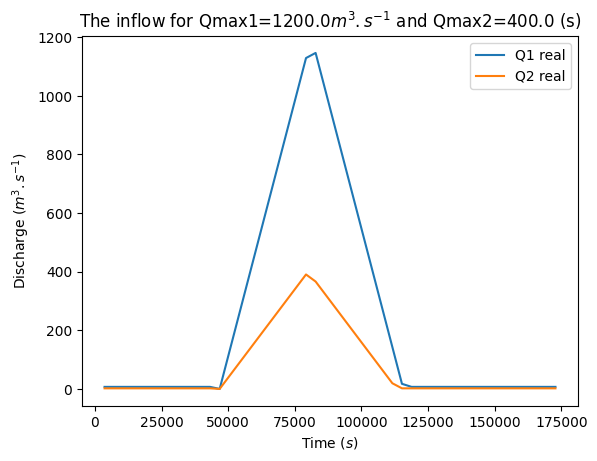

Snapshots shaps is (21801, 269)
cond of C= 4.863766863500525e+18


/home-local/allabou/Bureau/These/Code/Code_reduction/EA-POD-NN-REDUCTION/POD_Basis.py:97: RuntimeWarning: invalid value encountered in sqrt
  Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(self.Snapshots,self.Eigen_vec[:,i])


s_eigen = 1452013.2408419119
Duration: 0:00:03.018287


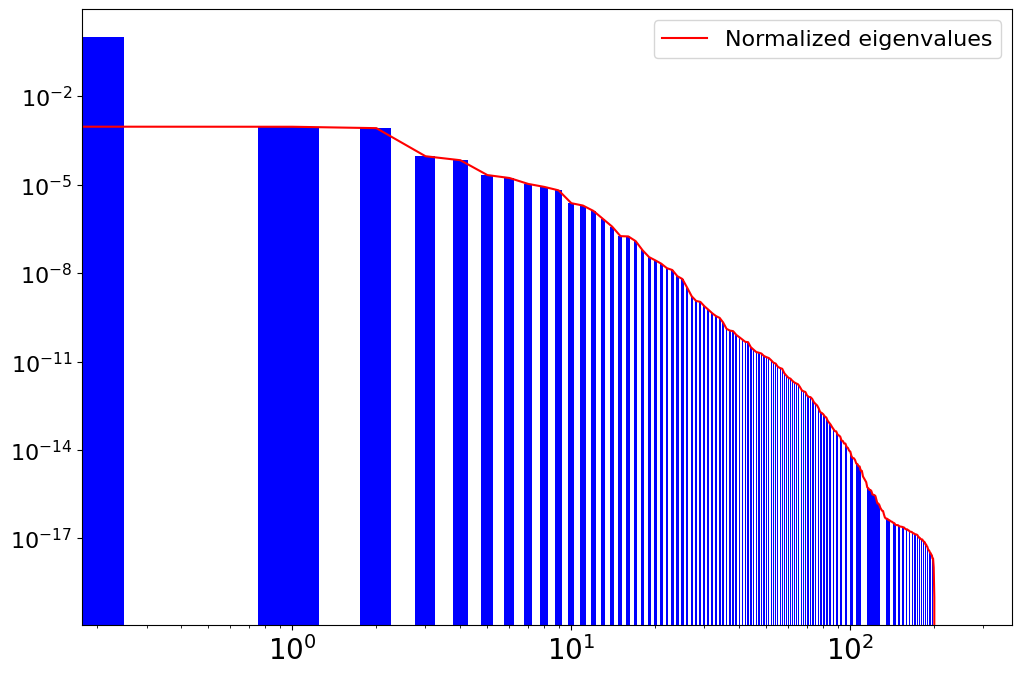

This corresponds to Nrb =  3
Brb shape is (21801, 3)
Nrb is equal to 3
Brb is of shape (21801, 3)
cond of C= 9.092527207891834e+19


/home-local/allabou/Bureau/These/Code/Code_reduction/EA-POD-NN-REDUCTION/POD_Basis_error.py:46: RuntimeWarning: invalid value encountered in sqrt
  Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(Snapshots,self.Eigen_vec[:,i])


Duration: 0:00:03.021585
s_eigen = 335.57042581879335


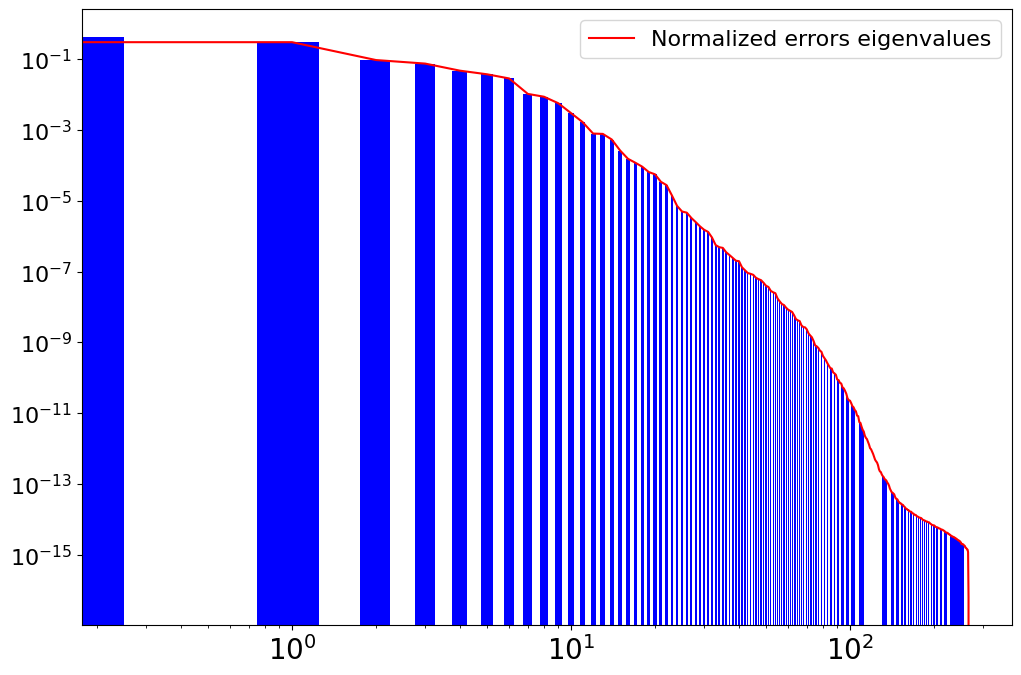

This corresponds to Ner =  10
Ber shape is (21801, 10)
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 20)                120       
                                                                 
 dense_1 (Dense)             (None, 20)                420       
                                                                 
 dense_2 (Dense)             (None, 20)                420       
                                                                 
 dense_3 (Dense)             (None, 20)                420       
                                                                 
 dense_4 (Dense)             (None, 20)                420       
                                                                 
 dense_5 (Dense)             (None, 20)                420       
                                                                 
 

2024-02-15 17:05:16.619197: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-02-15 17:05:16.641335: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-02-15 17:05:16.641445: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Physical devices cannot be modified after being initialized
len Urb_POD_train= (269, 3)
len Urb_POD_train_er= (269, 10)
len P= (269, 5)
len P_train= (188, 5)
len Urb_POD_train= (188, 3)
len Urb_POD_train_er= (188, 10)
len P_val= (54, 5)
len Urb_POD_val= (54, 3)
len Urb_POD_val_er= (54, 10)
len P_test= (27, 5)
len Urb_POD_test= (27, 3)
len Urb_POD_test_er= (27, 10)
Epoch 1/1000


2024-02-15 17:05:17.704223: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-15 17:05:17.930088: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f8c40c15170 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-02-15 17:05:17.930105: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA RTX A3000 Laptop GPU, Compute Capability 8.6
2024-02-15 17:05:17.933651: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-02-15 17:05:17.943249: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
I0000 00:00:1708013117.996600  387216 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


19/19 [==============================] - 2s 9ms/step - loss: 0.2804 - accuracy: 0.9468 - val_loss: 0.2329 - val_accuracy: 1.0000
Epoch 2/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.1398 - accuracy: 1.0000 - val_loss: 0.0089 - val_accuracy: 1.0000
Epoch 3/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0079 - accuracy: 1.0000 - val_loss: 0.0040 - val_accuracy: 1.0000
Epoch 4/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0026 - accuracy: 1.0000 - val_loss: 0.0025 - val_accuracy: 1.0000
Epoch 5/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0012 - accuracy: 1.0000 - val_loss: 0.0015 - val_accuracy: 1.0000
Epoch 6/1000
19/19 [==============================] - 0s 3ms/step - loss: 9.1230e-04 - accuracy: 1.0000 - val_loss: 0.0016 - val_accuracy: 1.0000
Epoch 7/1000
19/19 [==============================] - 0s 3ms/step - loss: 8.9456e-04 - accuracy: 1.0000 - val_loss: 0.0015 - val_accuracy: 1.0000
Epoch 8/100

Epoch 57/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6156e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 58/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6569e-04 - accuracy: 1.0000 - val_loss: 0.0014 - val_accuracy: 1.0000
Epoch 59/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6955e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 60/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6433e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000
Epoch 61/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.5481e-04 - accuracy: 1.0000 - val_loss: 0.0011 - val_accuracy: 1.0000
Epoch 62/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.7317e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000
Epoch 63/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.5609e-04 - accuracy: 1.0000 - val_loss: 0

... (30 outputs left out)

Epoch 780/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3032 - val_loss: 0.0025 - val_accuracy: 0.0741
Epoch 781/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3298 - val_loss: 0.0024 - val_accuracy: 0.1111
Epoch 782/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2553 - val_loss: 0.0024 - val_accuracy: 0.3704
Epoch 783/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3085 - val_loss: 0.0025 - val_accuracy: 0.1481
Epoch 784/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3085 - val_loss: 0.0024 - val_accuracy: 0.1111
Epoch 785/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2606 - val_loss: 0.0024 - val_accuracy: 0.1852
Epoch 786/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3298 - val_loss: 0.0024 - val_accuracy:

Epoch 837/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0069 - accuracy: 0.3085 - val_loss: 0.0024 - val_accuracy: 0.3704
Epoch 838/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3138 - val_loss: 0.0025 - val_accuracy: 0.1481
Epoch 839/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3245 - val_loss: 0.0023 - val_accuracy: 0.1481
Epoch 840/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3511 - val_loss: 0.0025 - val_accuracy: 0.1111
Epoch 841/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2926 - val_loss: 0.0024 - val_accuracy: 0.3704
Epoch 842/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0069 - accuracy: 0.2979 - val_loss: 0.0025 - val_accuracy: 0.1852
Epoch 843/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2500 - val_loss: 0.0025 - val_accuracy:

Epoch 894/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3138 - val_loss: 0.0023 - val_accuracy: 0.3704
Epoch 895/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3245 - val_loss: 0.0024 - val_accuracy: 0.1852
Epoch 896/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0069 - accuracy: 0.3404 - val_loss: 0.0024 - val_accuracy: 0.1481
Epoch 897/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3032 - val_loss: 0.0023 - val_accuracy: 0.3704
Epoch 898/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0024 - val_accuracy: 0.1481
Epoch 899/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0069 - accuracy: 0.3564 - val_loss: 0.0024 - val_accuracy: 0.1481
Epoch 900/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3085 - val_loss: 0.0025 - val_accuracy:

Epoch 951/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2926 - val_loss: 0.0024 - val_accuracy: 0.1111
Epoch 952/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3138 - val_loss: 0.0024 - val_accuracy: 0.1481
Epoch 953/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2766 - val_loss: 0.0026 - val_accuracy: 0.1481
Epoch 954/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2979 - val_loss: 0.0025 - val_accuracy: 0.1481
Epoch 955/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3511 - val_loss: 0.0023 - val_accuracy: 0.1852
Epoch 956/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.3511 - val_loss: 0.0024 - val_accuracy: 0.3704
Epoch 957/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.2234 - val_loss: 0.0025 - val_accuracy:

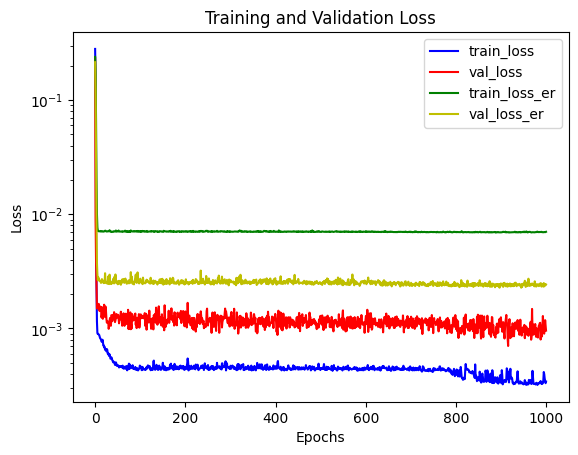

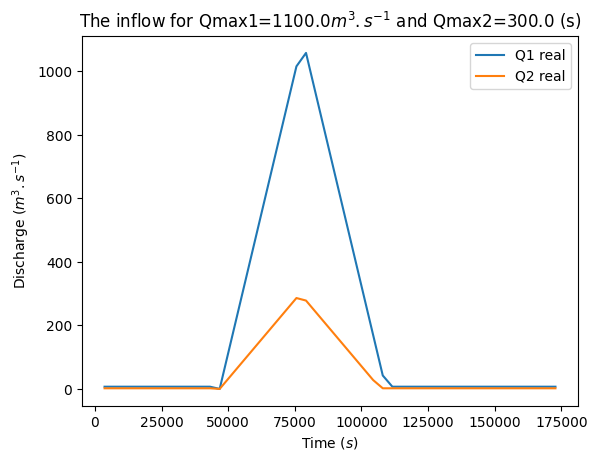

Number of elements in Time: 48
Number of elements in Flow1: 48
1/1 [==============================] - 0s 20ms/step
Uh_POD_NN shape (1, 21801)
(48,)
/home-local/allabou/Bureau/These/Code/Code_reduction/EA-POD-NN-REDUCTION
Printing case files 
 from /home-local/allabou/Bureau/dasshydro-main/cases/dev_case/Aude/built_bin  
  to  /home-local/allabou/Bureau/dasshydro-main/code/bin_A 
rm -rf ./bin_A/res/*
rm -rf ./bin_A/graph/*
rm -rf ./bin_A/min/*
clean= True
{'mesh_name': 'final_mesh.geo', 'ts': 216000.0, 'dta': 0, 'dtw': 10800.0, 'dtp': 60.0, 'dt': 0.1, 'temp_scheme': 'euler', 'spatial_scheme': 'first_b1', 'adapt_dt': 1, 'cfl': 0.5, 'feedback_inflow': 1, 'coef_feedback': 0.1, 'heps': 0, 'friction': 1, 'g': 10.0, 'w_tecplot': 0, 'w_vtk': 0, 'w_gnuplot': 1, 'w_obs': 0, 'use_obs': 0, 'max_nt_for_adjoint': 100000000, 'c_manning': 0, 'c_manning_beta': 0, 'c_bathy': 0, 'c_hydrograph': 1, 'c_ratcurve': 0, 'c_rain': 0, 'c_ic': 0, 'restart_min': 0, 'eps_min': 0}
call dassflow2d.wrapping.m_mesh.msh

(21801, 9)


2024-02-15 17:09:14.707 ( 252.710s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


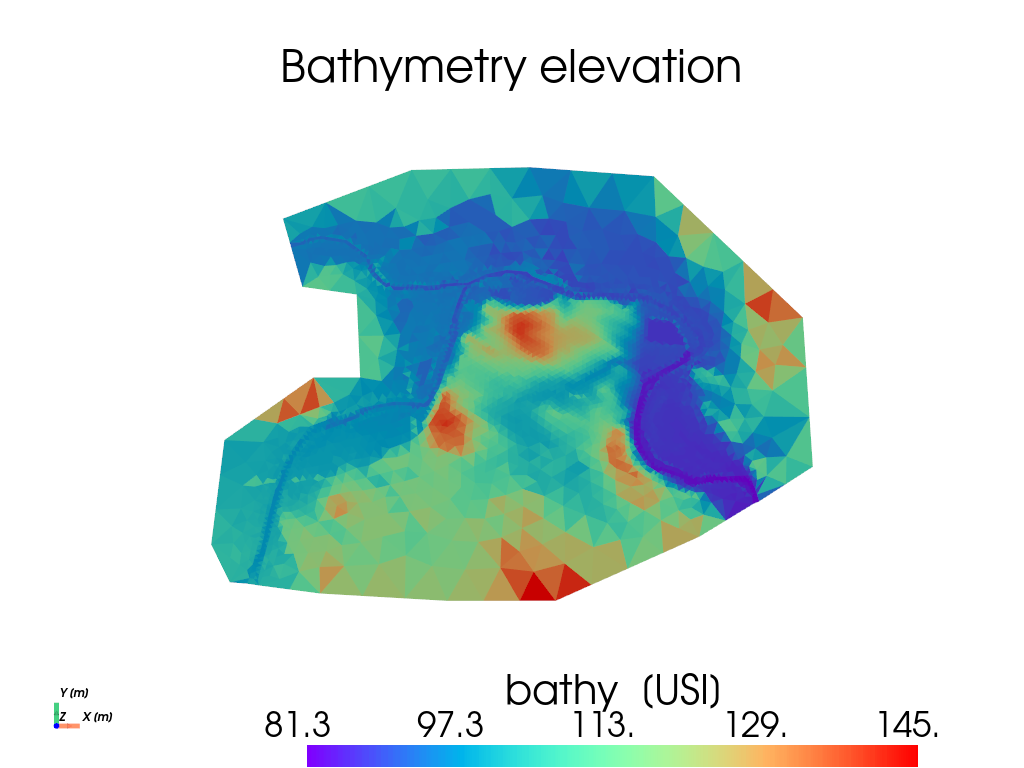

2024-02-15 17:09:14.919 ( 252.922s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


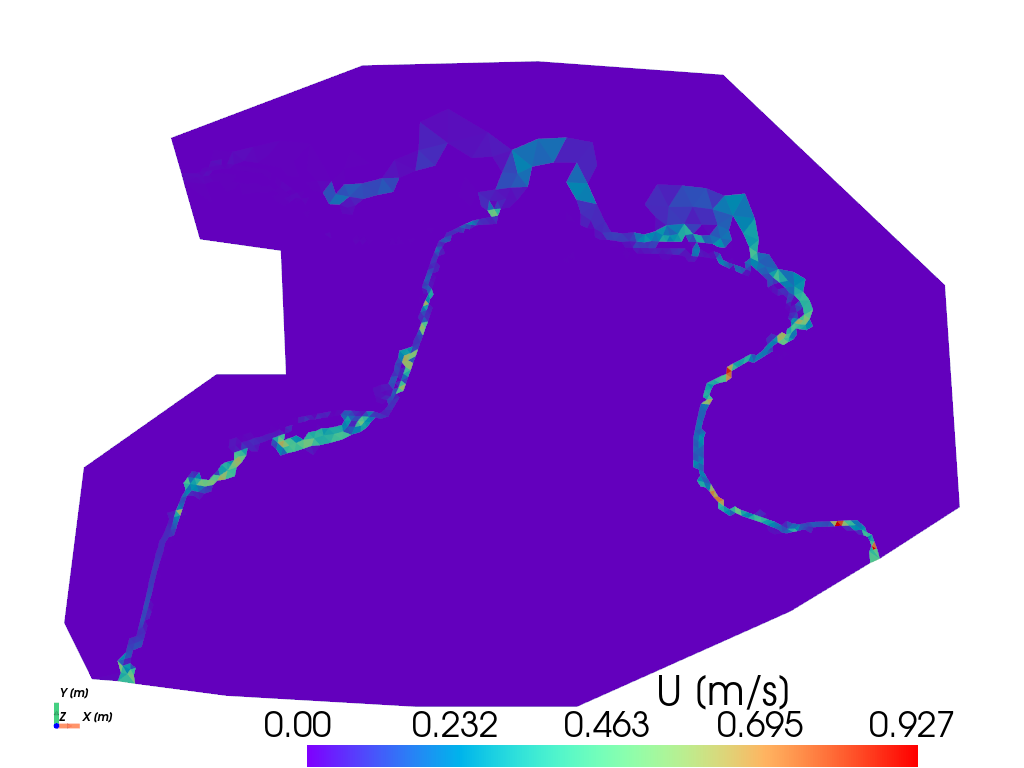

2024-02-15 17:09:15.013 ( 253.016s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


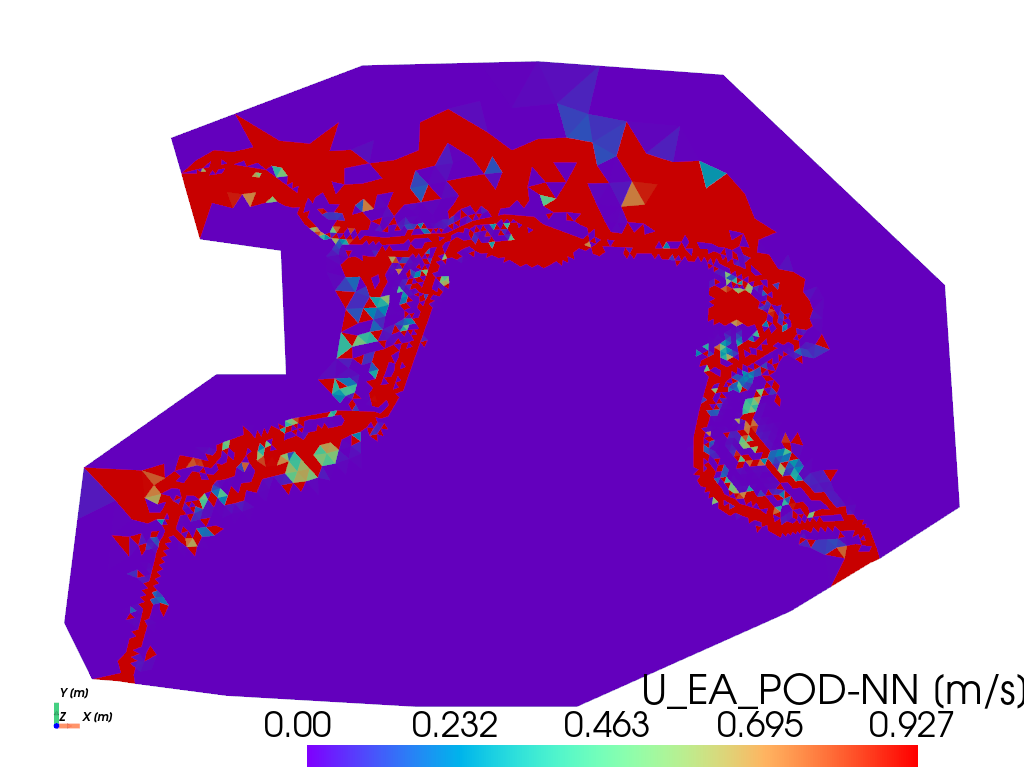

2024-02-15 17:09:15.116 ( 253.119s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


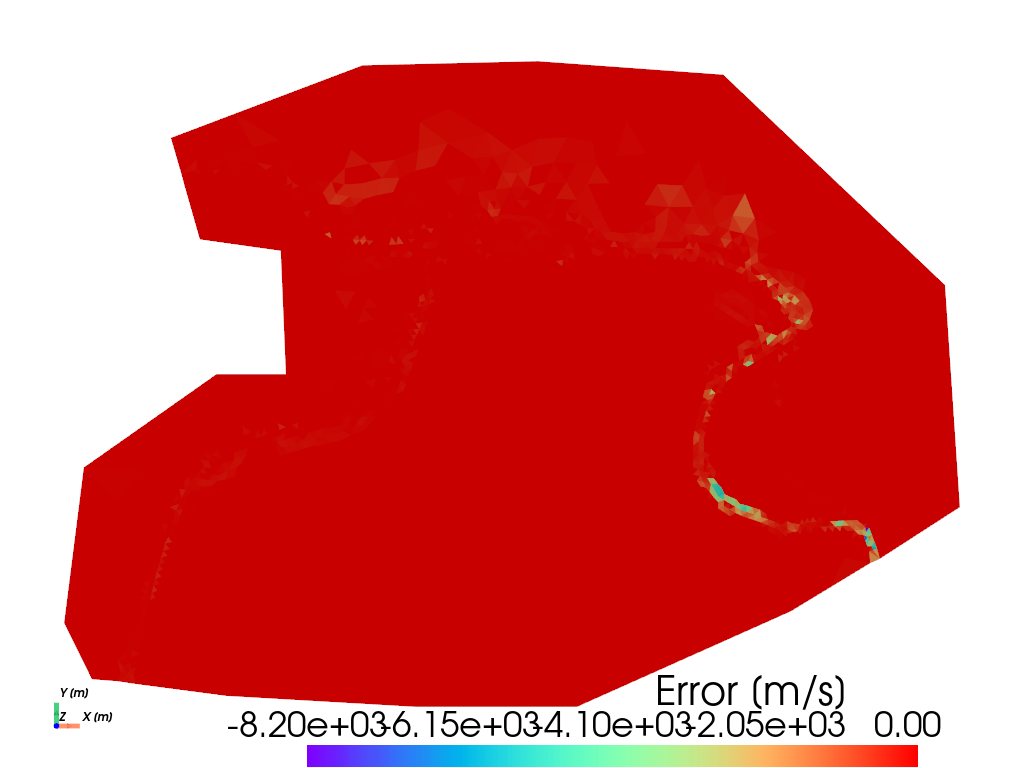

2024-02-15 17:09:15.214 ( 253.217s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


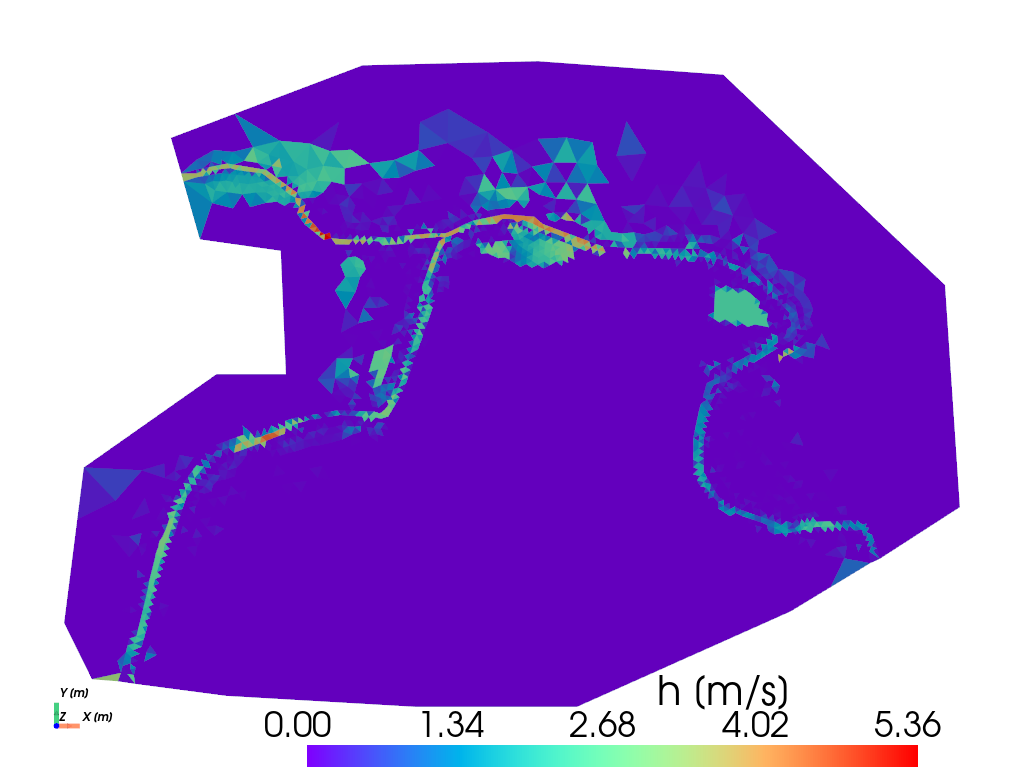

2024-02-15 17:09:15.316 ( 253.320s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


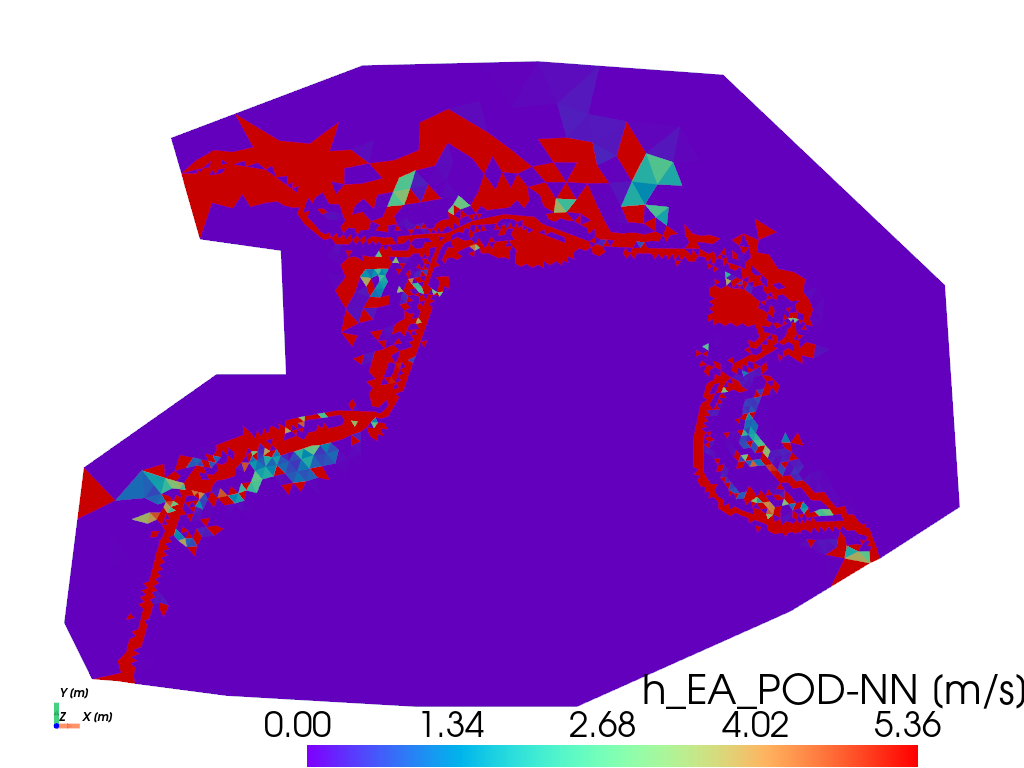

2024-02-15 17:09:15.415 ( 253.418s) [    7F8E31F21280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


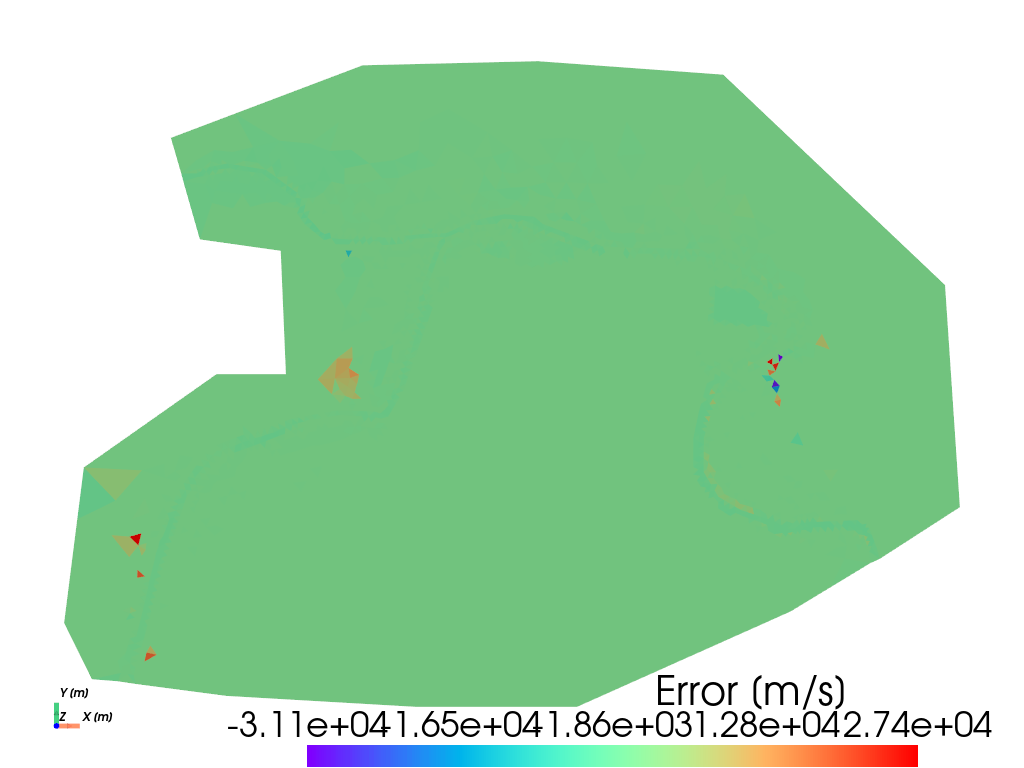

/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

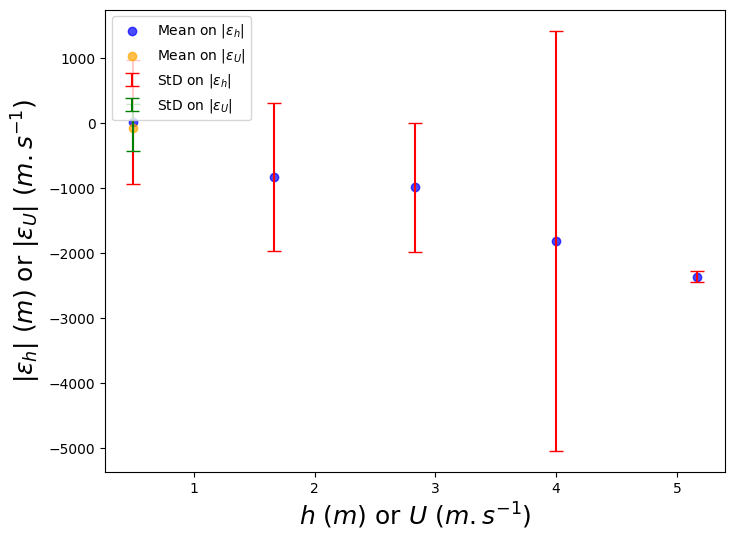

data_h= (7267,)
mu_h= 235.2531557185488
std_h= 1061.4042701292424
cdf_h= [0.41229578 0.41229578 0.72191937 ... 0.9091355  0.45193621 0.89082374]
data_u= (7267,)
mu_u= 69.14982217330447
std_u= 361.0924161285842
cdf_u= [0.42406626 0.42406626 0.43092082 ... 0.43042924 0.92606615 0.67549411]


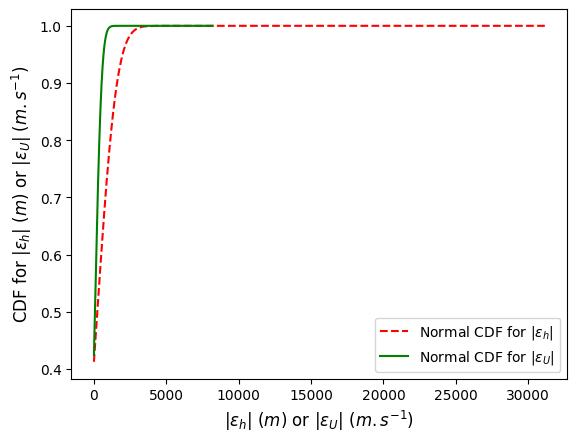

madiane of h is 0.0005339747180721167
madiane of u is 4.8737166645301655e-05


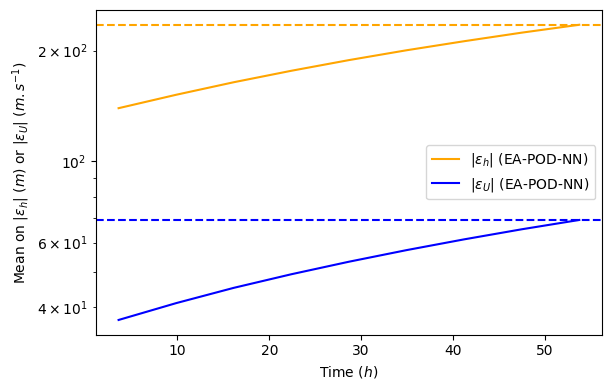

In [3]:
if __name__ == "__main__":
   
    ###########################################################################
    # Parameter space construction
    ###########################################################################
    
    # Construct the parameter space using HydrographGenerator
    hydrograph_generator = HydrographGenerator()
    
    # Check the parameter constraint (phase-shofted with 3.5%)
    hydrograph_generator.check_constraint(*hydrograph_params['constraint_values'])
    
    # Construct the parameter space
    parameter_space = hydrograph_generator.generate_parameter_space(
        hydrograph_params['mu1_range'],
        hydrograph_params['mu2_range'],
        hydrograph_params['mu3_range'],
        hydrograph_params['mu4_range'],
        hydrograph_params['constraint_values'][1]
    )
    echantillons = np.array(parameter_space)
    
    # Plot the parameter space
    hydrograph_generator.plot_parameter_space(
        echantillons,
        hydrograph_params['param'],
        hydrograph_params['tmontee1'],
        hydrograph_params['tmontee2']
    )

    # Define the hydrographs numpy vectors
    Qin1, Qin2 = hydrograph_generator.generate_hydrographs(echantillons, hydrograph_params['tmontee1'], hydrograph_params['tmontee2'])
   
    # Update the dictionary with the desired values
    dassflow_params['Qin1'] = Qin1
    dassflow_params['Qin1'] = Qin2
    
    # Construct the parameter set for the EA-POD-NN method
    POD_NN_Parameters = hydrograph_generator.generate_pod_nn_parameters(echantillons, hydrograph_params['tmontee1'], hydrograph_params['tmontee2'])

    # Update the dictionary with the desired values
    my_nn_params['input_dim'] = len(POD_NN_Parameters[0])
    
    # ##########################################################################
    # # Snapshots computation
    # ##########################################################################
    
    # # Configure the logging system to output log messages with a severity level of DEBUG
    # logging.basicConfig(level=logging.DEBUG)
    # print(os.path.abspath("."))
    
    # # Define the DassFlow class with corresponding paths
    # dassflow_runner = DassFlowRunner(
    #     dassflow_params['dassflow_dir'],
    #     dassflow_params['code_dir'],
    #     dassflow_params['save_dir']
    # )
    
    # # Copy the case files
    # dassflow_runner.copy_case_files(os.path.join(dassflow_params['code_dir'], "bin_A"))
    
    # # Initialize the model
    # dassflow_runner.initialize_model(os.path.join(dassflow_params['code_dir'], "bin_A"))
    
    # # Set the hydrographs vectors
    # dassflow_runner.set_qin_data(dassflow_params['Qin1'], dassflow_params['Qin2'])
    
    # # Run the DassFlow simulation in parallel
    # dassflow_runner.run_simulations(16, dassflow_params['run_type'], dassflow_params['ts'], dassflow_params['dtw'])
   
    ###########################################################################
    # Reduced basis Brb and Reduced basis Ber computation
    ###########################################################################
    
    # Compute the RB matrix Brb
    
    # Initialize the POD processor
    pod_processor = PODProcessor(**pod_params)
    
    # Read the hdf5 files and construct the snapshots matrix
    Snapshots = pod_processor.read_data_files()
    print('Snapshots shaps is',Snapshots.shape)
    
    # Comute the eigen values of the correlation matrix C
    pod_processor.compute_eigenvalues()
    
    # Compute and plot the eigenvalues and eigenvectors of C
    pod_processor.plot_eigenvalues()
    
    # Truncate the first Nrb modes
    Nrb = pod_processor.compute_number_of_modes(pod_params['epsilon_POD'])
    # Update the dictionary with the desired values
    my_nn_params['Nrb'] = Nrb
        
    
    # Verify the error estimtion of POD method
    # pod_processor.compute_error_estimation()  # Uncomment this line if needed
    
    # Get the RB matrix
    Brb = pod_processor.truncate_reduced_basis(Nrb)
    
    # Compute the RB matrix Ber
    
    # Initialize the POD  error processor
    pod_processor_er = PODProcessor_error(**pod_params_er)
    
    # Comute the eigen values of the correlation matrix C
    pod_processor_er.compute_eigenvalues_er(Snapshots,Nrb,Brb)
    
    # Compute and plot the eigenvalues and eigenvectors of C
    pod_processor_er.plot_eigenvalues_er() 
    
    # Truncate the first Nrb modes
    Ner = pod_processor_er.compute_number_of_modes_er(pod_params_er['epsilon_er'])

    # Update the dictionary with the desired values
    my_nn_params['Ner'] = Ner
    my_nn_params['Neurons_er'] = 2 * Ner
    
    # Get the RB matrix
    Ber = pod_processor_er.truncate_reduced_basis_er(Ner)
   
    ###########################################################################
    # EA-POD-NN method: offline phase 
    ###########################################################################
    
    # Initialize the NN parameters
    my_nn = POD_NN_METHOD(**my_nn_params)
    
    # Load the data
    my_nn.load_data()
    
    # Normalize the data
    my_nn.Urb_POD,Urb_POD_max,Urb_POD_min = my_nn.normalize_data(my_nn.Urb_POD)
    my_nn.Urb_POD_er,Urb_POD_er_max,Urb_POD_er_min = my_nn.normalize_data(my_nn.Urb_POD_er)
    my_nn.P,P_max,P_min = my_nn.normalize_data(my_nn.P)
    
    # Split data into train, test and validation parts
    my_nn.split_data()
    
    # Train the NN 
    history,history_er = my_nn.train_models()
    #history_er = my_nn.train_model_er()
    
    # Evaluate the NN model on the validation data
    my_nn.evaluate_model()
    
    # Plot the loss function of the NN 
    my_nn.plot_loss(history,history_er)
    
    # Save the optimized NN parameters
    my_nn.save_model('Neural-network-1','Neural-network-2')
   
    ###########################################################################
    # EA-POD-NN method: online phase
    ###########################################################################
    
    # Computation of the hydrographs to simulate the reference solution
    hydrograph_generator.generate_hydrograph_online(np.zeros(hydrograph_params['n']), np.zeros(hydrograph_params['n']),
                                                    hydrograph_generator.Time, hydrograph_params['tmontee1'], hydrograph_params['param'])
    

    # Instantiate the class with required parameters
    pod_nn_prediction = POD_NN_PREDICTION(my_nn.model,my_nn.model_er, Brb, Ber, P_max,P_min,
                                          Urb_POD_max,Urb_POD_min,Urb_POD_er_max,Urb_POD_er_min)

    # Use the method to predict solution
    h_POD_NN, norm_vel_POD_NN = pod_nn_prediction.predict_solution(my_nn, hydrograph_params['param'],
                                                                   hydrograph_generator.Time_simu,len(Brb))
    
    
    ###########################################################################
    # Compute the reference solution for the online phase
    ###########################################################################
    
    # Initialise the simulation
    simulation = DassflowSimulation()
    
    # Load the inflows vectors
    simulation.load_inflow('Q_1.npy', 'Q_2.npy')
    
    # Setup the directories for the simulation
    simulation.setup_directories("/home-local/allabou/Bureau/dasshydro-main")
    
    # Initialize the dassFlow model
    simulation.initialize_model()
    
    # Get the boundary conditions
    simulation.get_boundary_conditions()
    
    # Run the simulation
    simulation.run_simulation()
    
    # Get the model outputs: h the water depth and nor_vel the velocity norm
    h, norm_vel = simulation.get_output('/home-local/allabou/Bureau/These/Code/Code_reduction/Dassflow_sol.npy')
    
    # Plot the bathymetry
    simulation.plot_bathy()
    
    # Compute the absoolute error between the reference solution and EA-POD-NN one
    Vel_error = simulation.error_computation(norm_vel, norm_vel_POD_NN)
    h_error = simulation.error_computation(h, h_POD_NN)
    
    # Plot the velocity norm outputs
    simulation.plot_velocity_outputs(norm_vel[:, -1], norm_vel_POD_NN[:, -1], Vel_error[:, -1])
    
    # Plot the water depth outputs
    simulation.plot_water_depth_outputs(h[:, -1], h_POD_NN[:, -1], h_error[:, -1])
    
    # Plot the histograme of the error on the water depth and velocity norm
    simulation.plot_error_histogram(h[:, -1], h_error[:, -1], norm_vel[:, -1], Vel_error[:, -1], np.linspace(0, 7, 7), np.linspace(0, 7, 6))

    # Compute and plot the Cummulative Distribution Function (CDF)
    simulation.plot_cdf(h_error[:, -1], Vel_error[:, -1])
    
    # Compute the means error in function of time
    simulation.plot_mean_errors(h_error, Vel_error)
    